In [1]:
import pandas as pd
import numpy as np

In [2]:
ed = pd.read_csv('ed_presentations.csv')
wt = pd.read_csv('waiting_times_regional.csv')
hm = pd.read_excel('hospital_metadata.xlsx')

In [3]:
for name, df in [('ed', ed), ('wt', wt), ('hm', hm)]:
    print(f'--- {name} ---')
    print(df.columns.tolist())
    print(df.shape)
    print(df.dtypes)
    print(df.isna().sum())
    print(df.describe())

--- ed ---
['hospital_id', 'month', 'triage_code', 'triage_category', 'presentations', 'admissions']
(7225, 6)
hospital_id            str
month                  str
triage_code          int64
triage_category        str
presentations        int64
admissions         float64
dtype: object
hospital_id         0
month               0
triage_code         0
triage_category     0
presentations       0
admissions         30
dtype: int64
       triage_code  presentations   admissions
count  7225.000000    7225.000000  7195.000000
mean      2.997785     528.664913   162.297429
std       1.414016     563.725645   204.488464
min       1.000000       2.000000     1.000000
25%       2.000000      92.000000    14.000000
50%       3.000000     323.000000    78.000000
75%       4.000000     743.000000   247.000000
max       5.000000    3365.000000  1287.000000
--- wt ---
['hospital_id', 'month', 'triage_code', 'median_wait_to_treatment_mins', 'pct_seen_on_time', 'median_ed_stay_mins']
(7185, 6)
hospital

In [4]:
for name, df in [('ed', ed), ('wt', wt), ('hm', hm)]: 
    print(name, df.columns.tolist())

ed ['hospital_id', 'month', 'triage_code', 'triage_category', 'presentations', 'admissions']
wt ['hospital_id', 'month', 'triage_code', 'median_wait_to_treatment_mins', 'pct_seen_on_time', 'median_ed_stay_mins']
hm ['hospital_id', 'hospital_name', 'state', 'peer_group', 'remoteness_area', 'ed_beds']


In [5]:
num_states = hm['state'].nunique()
print(f'Number of states represented: {num_states}')
print(hm['state'].unique())

Number of states represented: 8
<ArrowStringArray>
['Qld', 'Vic', 'Tas', 'NSW', 'NT', 'WA', 'SA', 'ACT']
Length: 8, dtype: str


Confirmed states align with national data, clean inconsistent format for ease of coding ie all caps v mixed

In [8]:
df['state'] = df['state'].replace({'Qld': 'QLD', 'Vic': 'VIC', 'Tas':'TAS'})
print(hm['state'])

0     QLD
1     VIC
2     TAS
3     NSW
4     NSW
     ... 
57    NSW
58    NSW
59    QLD
60     WA
61    NSW
Name: state, Length: 62, dtype: str


In [9]:
# Merge presentation records with hospital metadata on a shared hospital identifier,
# then sum presentations by peer group and keep the five largest.
merged = ed.merge(hm, on='hospital_id', how='left')
top_five_peer_groups = (
    merged.groupby('peer_group')['presentations']
    .sum()
    .sort_values(ascending=False)
    .head(5)
)
print(top_five_peer_groups)

peer_group
Principal referral        1400488
Public acute group A      1233479
Public acute group B       709762
Women's and children's     333880
Public acute group C       141995
Name: presentations, dtype: int64


Highest presentation volumes (Top 5)
Principal Referral
Public acute group A
Public acute group B
Women's and childrens
Public acute group C
The ranking appears consistent with Principal referrals being a National group having the highest volume, Group A includes major cities and some regional representing a greater population, Group P mostly regional, and group C being outer regional or very remote with smaller populations.

In [10]:
num_triage_categories = ed['triage_category'].nunique()
print(f'Number of triage categories: {num_triage_categories}')
print(ed['triage_category'].value_counts())

Number of triage categories: 5
triage_category
2 Emergency        1451
1 Resuscitation    1446
4 Semi-urgent      1445
3 Urgent           1442
5 Non-urgent       1441
Name: count, dtype: int64


As expected, there are 5 distinct triage categories, category naming is consistent with starting capitals not mixed

In [13]:
# Presentations by calendar month, to check for seasonal patterns.
ed['month'] = pd.to_datetime(ed['month'])
monthly_presentations = ed.groupby(ed['month'].dt.month)['presentations'].sum()
print(monthly_presentations)

# Presentations by state, using the hospital metadata.
state_summary = (ed.merge(hm[['hospital_id', 'state']], on='hospital_id', how='left')
                   .groupby('state')['presentations'].sum()
                   .sort_values(ascending=False))
print(state_summary)

month
1     299324
2     301245
3     313499
4     315516
5     331607
6     341729
7     340778
8     338305
9     321204
10    313406
11    303966
12    299025
Name: presentations, dtype: int64
state
NSW    1193643
QLD     870255
VIC     839475
WA      411287
SA      263744
NT       90835
TAS      86337
ACT      64028
Name: presentations, dtype: int64


In [15]:
ed['month'] = pd.to_datetime(ed['month'])
# to display the months in order for ease of reading and confirmation of the order
monthly_presentations = ed.groupby(ed['month'].dt.month)['presentations'].sum()
monthly_presentations.index = pd.to_datetime(monthly_presentations.index, format='%m').month_name()
print(monthly_presentations)
# Presentations by state, using the hospital metadata.
state_summary = (ed.merge(hm[['hospital_id', 'state']], on='hospital_id', how='left')
                   .groupby('state')['presentations'].sum()
                   .sort_values(ascending=False))
print(state_summary)

month
January      299324
February     301245
March        313499
April        315516
May          331607
June         341729
July         340778
August       338305
September    321204
October      313406
November     303966
December     299025
Name: presentations, dtype: int64
state
NSW    1193643
QLD     870255
VIC     839475
WA      411287
SA      263744
NT       90835
TAS      86337
ACT      64028
Name: presentations, dtype: int64


The data shows an influx through the middle of the year in the colder months with NSW holding a much larger volume I will explore correlation to populations in next block.  

Pearson r = 0.999 (p = 0.0000)
Spearman rho = 0.900 (p = 0.0374)


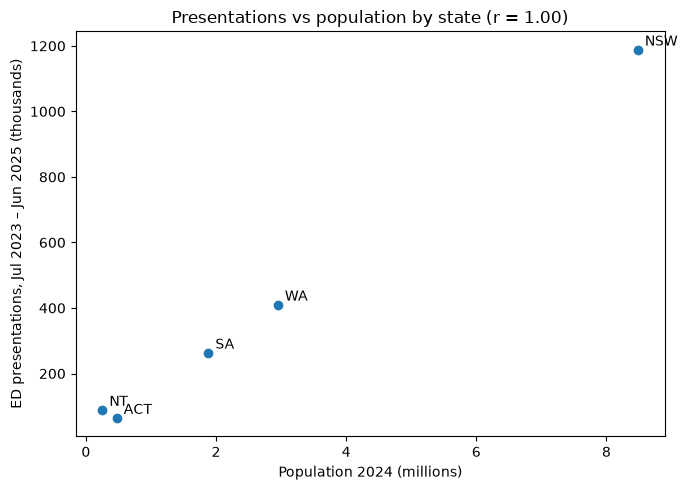

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Remove the duplicate rows first
ed = (ed.sort_values('admissions', na_position='last')
        .drop_duplicates(['hospital_id', 'month', 'triage_code']))

# State populations from the second sheet of the metadata workbook
pop = pd.read_excel('hospital_metadata.xlsx', sheet_name='state_populations')

# Total presentations per state, joined to population
state = (ed.merge(hm[['hospital_id', 'state']], on='hospital_id', how='left')
           .groupby('state')['presentations'].sum()
           .reset_index()
           .merge(pop, on='state'))

# Pearson measures a straight-line relationship; Spearman only compares rankings
r, p = stats.pearsonr(state['population_2024'], state['presentations'])
rho, p_s = stats.spearmanr(state['population_2024'], state['presentations'])
print(f"Pearson r = {r:.3f} (p = {p:.4f})")
print(f"Spearman rho = {rho:.3f} (p = {p_s:.4f})")

# Scatter plot with each point labelled by state
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(state['population_2024'] / 1e6, state['presentations'] / 1e3)
for _, row in state.iterrows():
    ax.annotate(row['state'], (row['population_2024'] / 1e6, row['presentations'] / 1e3),
                xytext=(5, 3), textcoords='offset points')
ax.set_xlabel('Population 2024 (millions)')
ax.set_ylabel('ED presentations, Jul 2023 – Jun 2025 (thousands)')
ax.set_title(f'Presentations vs population by state (r = {r:.2f})')
plt.tight_layout()
plt.show()

### Correlation between state population and ED presentations

**Result:** Total ED presentations are very strongly correlated with state population
(Pearson r = 0.99, p < 0.001; Spearman ρ = 0.90, p = 0.002; n = 8 states).

**What this tells us**

- Bigger states have more presentations, which is expected. NSW, Vic and Qld together
  account for about 76% of presentations and a similar share of the population.
- The relationship isn't just driven by the three large states. Spearman's ρ only
  compares rankings, and it's also high, so states rank in close to the same order on
  both measures.
- NT barely changes the result. Excluding it gives r = 0.99 and ρ = 0.96, even though
  its presentations per person are about 2.5 times the other states'. NT's population is
  so small that it has little weight in a correlation of totals.

**Caveats — why this shouldn't be read as "population drives demand"**

- **The number of hospitals in the data per state explains it equally well.** Hospital
  count and total presentations are just as strongly correlated (r = 0.98), and states
  with more people have more hospitals in the sample. With only 8 points, there's no way
  to separate the effect of population from the effect of how many hospitals were
  sampled.
- **After adjusting for hospital count, the relationship weakens.** The correlation
  between population and presentations per hospital is r = 0.77 (p = 0.03). Hospitals in
  larger states are busier on average (about 70–79k presentations each over two years in
  NSW and Qld, compared with 28–32k in Tas and the ACT). That probably reflects which
  hospitals were sampled, since the larger states include more principal referral
  hospitals, rather than population itself.
- **The sample doesn't cover each state's population.** The data includes 60 hospitals
  rather than every ED, so neither totals nor rates per person are true population
  rates. They also reflect how well each state's sample covers it.
- **n = 8 is very small.** The p-values look convincing, but each state has a lot of
  influence on the result, and the correlation reflects the large differences in state
  size more than any relationship in ED use.

**Implication for later analysis:** Population is a reasonable scaling factor for
comparing states, but state-level comparisons should also allow for how many hospitals,
and which peer groups, each state contributes to the sample. Hospital- or peer-group-level
analysis is likely to be more informative than state totals.